In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_next
score

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
df = pd.read_csv(
    r"C:\Student-Exam-Score-Predictor\dataset\student_data_cleaned.csv"
)

print("Dataset loaded successfully")
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully
Shape: (6607, 20)

Columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [3]:
X = df.drop("Exam_Score", axis=1)
y = df["Exam_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget variable: Exam_Score")

Features shape: (6607, 19)
Target shape: (6607,)

Target variable: Exam_Score


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5285
Testing samples: 1322


In [5]:
model_path = r"C:\Student-Exam-Score-Predictor\models\best_model.pkl"

best_model = joblib.load(model_path)

print("Best model loaded successfully")
print("Model:", best_model)

Best model loaded successfully
Model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Hours_Studied',
                                                   'Attendance', 'Sleep_Hours',
                                                   'Previous_Scores',
                                                   'Tutoring_Sessions',
                                                   'Physical_Activity']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
     

In [6]:
y_pred = best_model.predict(X_test)

print("Predictions generated successfully")
print("Number of predictions:", len(y_pred))
print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully
Number of predictions: 1322

First 10 predictions:
[64.52628302 65.2651138  71.53126265 64.27748146 66.5216532  66.61246339
 72.47094891 66.49826901 69.98604472 70.13327106]


In [7]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("BEST MODEL EVALUATION")
print("---------------------")
print("MSE  :", mse)
print("RMSE :", rmse)
print("R²   :", r2)

BEST MODEL EVALUATION
---------------------
MSE  : 3.2560199870428943
RMSE : 1.804444509272284
R²   : 0.7696495724907312


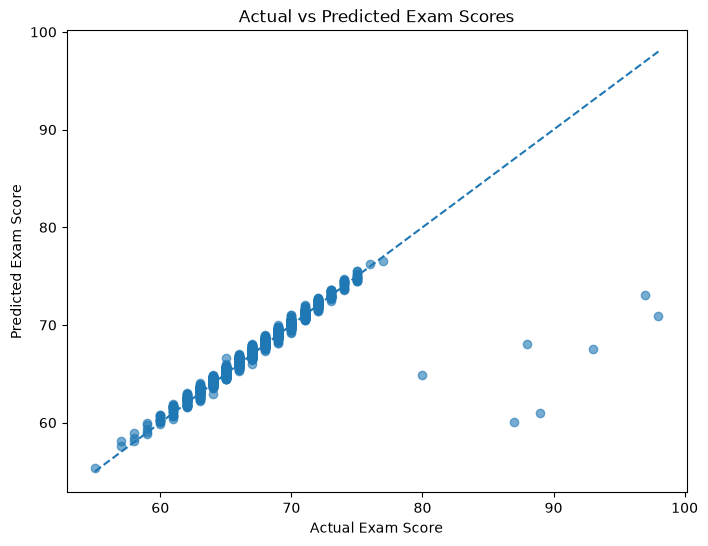

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")

plt.show()

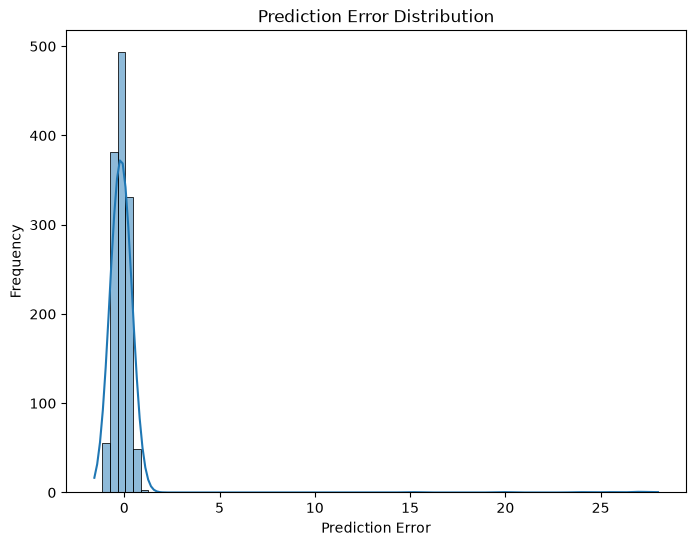

In [9]:
errors = y_test - y_pred

plt.figure(figsize=(8, 6))

sns.histplot(errors, kde=True)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution")

plt.show()

In [10]:
evaluation_results = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "R²"],
    "Value": [mse, rmse, r2]
})

print(evaluation_results)

  Metric     Value
0    MSE  3.256020
1   RMSE  1.804445
2     R²  0.769650


In [11]:
# Model comparison

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MSE": [
        3.2560199870428943,
        4.660667397881997
    ],
    "RMSE": [
        1.804444509272284,
        2.1588578920072523
    ],
    "R²": [
        0.7696495724907312,
        0.6702763705834445
    ]
})

print(comparison)

                      Model       MSE      RMSE        R²
0         Linear Regression  3.256020  1.804445  0.769650
1  Random Forest Regression  4.660667  2.158858  0.670276


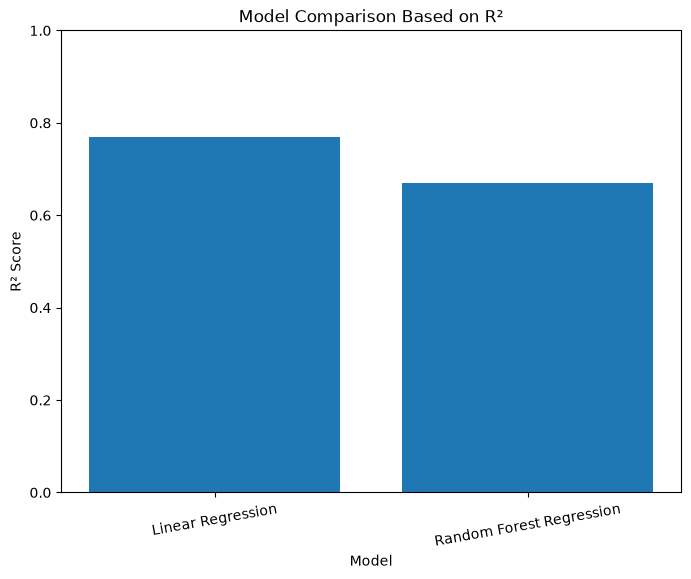

In [12]:
plt.figure(figsize=(8, 6))

plt.bar(comparison["Model"], comparison["R²"])

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Model Comparison Based on R²")

plt.ylim(0, 1)
plt.xticks(rotation=10)

plt.show()

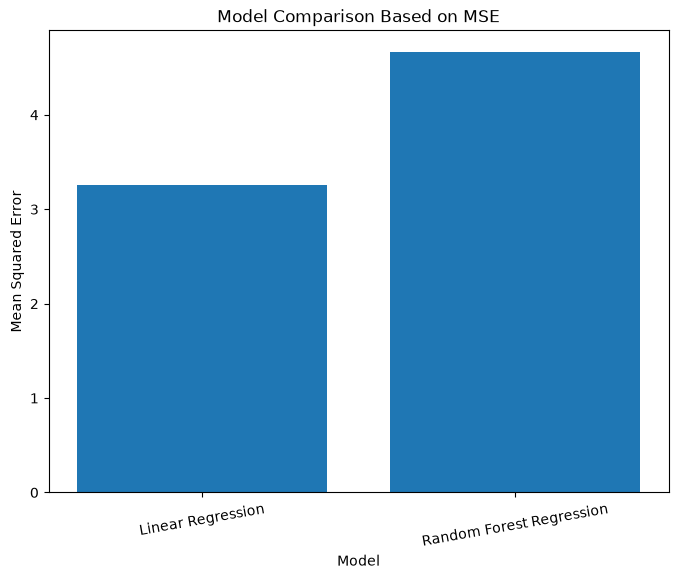

In [13]:
plt.figure(figsize=(8, 6))

plt.bar(comparison["Model"], comparison["MSE"])

plt.xlabel("Model")
plt.ylabel("Mean Squared Error")
plt.title("Model Comparison Based on MSE")

plt.xticks(rotation=10)

plt.show()

In [14]:
best_model_name = comparison.loc[
    comparison["R²"].idxmax(), "Model"
]

print("FINAL MODEL SELECTION")
print("---------------------")
print("Best Model:", best_model_name)
print("Reason: Highest R² and lowest MSE among the two models.")

FINAL MODEL SELECTION
---------------------
Best Model: Linear Regression
Reason: Highest R² and lowest MSE among the two models.


In [15]:
print("=" * 50)
print("STUDENT EXAM SCORE PREDICTOR")
print("FINAL MODEL EVALUATION SUMMARY")
print("=" * 50)

print("\nLinear Regression:")
print("MSE  :", comparison.loc[0, "MSE"])
print("RMSE :", comparison.loc[0, "RMSE"])
print("R²   :", comparison.loc[0, "R²"])

print("\nRandom Forest Regression:")
print("MSE  :", comparison.loc[1, "MSE"])
print("RMSE :", comparison.loc[1, "RMSE"])
print("R²   :", comparison.loc[1, "R²"])

print("\nSelected Model: Linear Regression")
print("The Linear Regression model provides the best performance.")

STUDENT EXAM SCORE PREDICTOR
FINAL MODEL EVALUATION SUMMARY

Linear Regression:
MSE  : 3.2560199870428943
RMSE : 1.804444509272284
R²   : 0.7696495724907312

Random Forest Regression:
MSE  : 4.660667397881997
RMSE : 2.1588578920072523
R²   : 0.6702763705834445

Selected Model: Linear Regression
The Linear Regression model provides the best performance.
